In [24]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math
import datetime

from scipy import signal
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t as t_dist
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
import matplotlib.colors as mplcolors
from matplotlib.ticker import FixedLocator
from matplotlib.ticker import AutoMinorLocator
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch, Rectangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

In [2]:
# ============================================================
# 重みづけ最小二乗フィット（1次関数） y = a*x + b
# ============================================================

def weighted_linear_fit(x, y, w):
    """
    重みづけ最小二乗フィット (1次関数)

    Parameters
    ----------
    x     : array-like  説明変数
    y     : array-like  目的変数
    sigma : array-like  各点の標準偏差（測定誤差）

    Returns
    -------
    a, b        : フィット係数 (y = a*x + b)
    sigma_a, sigma_b : 各係数の標準誤差
    """
    # 重みづけ和
    Sw = np.sum(w)
    Swx = np.sum(w * x)
    Swx2 = np.sum(w * x**2)
    Swy = np.sum(w * y)
    Swxy = np.sum(w * x * y)

    # 行列式
    delta = Sw * Swx2 - Swx**2

    # 解析解
    a = (Sw * Swxy - Swx * Swy) / delta
    b = (Swx2 * Swy - Swx * Swxy) / delta

    # 標準誤差
    sigma_a = np.sqrt(Sw / delta)
    sigma_b = np.sqrt(Swx2 / delta)

    return a, b, sigma_a, sigma_b

In [3]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [4]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [5]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492*1E+3  # Jupiter radius [m]
RE = 1560*1E+3   # Europa radius [m]
# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

Psyn_eu = (11.22)*3600      # Moon's synodic period [sec]
Psyn_ga = (10.53)*3600      # Moon's synodic period [sec]

In [6]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b3_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')

# PJ6のデータを読み込む

In [7]:
PJ_num = 6
date_list = ['2017DOY136', '2017DOY137', '2017DOY138',
             '2017DOY139', '2017DOY140', '2017DOY141',]

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

In [8]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ======================
# Con2020 original value
jm.Con2020.Config(
    mu_i=con20_mu_i_tot[np.where(con20_pj_idx == 6)],
    i_rho=con20_mu_i_rho[np.where(con20_pj_idx == 6)],
)
dBx1_pc = np.zeros(time_arr.size)
dBy1_pc = np.zeros(time_arr.size)
dBz1_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    dBx1_pc[i], dBy1_pc[i], dBz1_pc[i] = jm.Con2020.Field(rx_pc[i],
                                                          ry_pc[i],
                                                          rz_pc[i])  # [nT]
dBr1_pc = dBx1_pc*sin_theta*cos_phi + dBy1_pc * \
    sin_theta*sin_phi + dBz1_pc*cos_theta
dBtheta1_pc = dBx1_pc*cos_theta*cos_phi + \
    dBy1_pc*cos_theta*sin_phi - dBz1_pc*sin_theta
dBphi1_pc = -dBx1_pc*sin_phi + dBy1_pc*cos_phi

Distance [RJ]: 44.09285625971904 39.84420692636267


In [9]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=2.19129985E-6,
        MLT0=2.46607518,
        a1=-5.12302579,
        MLT1=-16.93107288,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

4.6363636363636356e-05 8.449286687704634


In [10]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx1_cs, dBy1_cs, dBz1_cs = csfield._sys3_2_cs(dBx1_pc, dBy1_pc, dBz1_pc)
dBrho1_cs = dBx1_cs*np.cos(phi_cs) + dBy1_cs*np.sin(phi_cs)
dBphi1_cs = -dBx1_cs*np.sin(phi_cs) + dBy1_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 2.8606647875041236


In [11]:
# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr1_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta1_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi1_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr1_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta1_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi1_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (Con2020):', RMS_total)

RMS total (Con2020): 2.9336969564063686


In [12]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

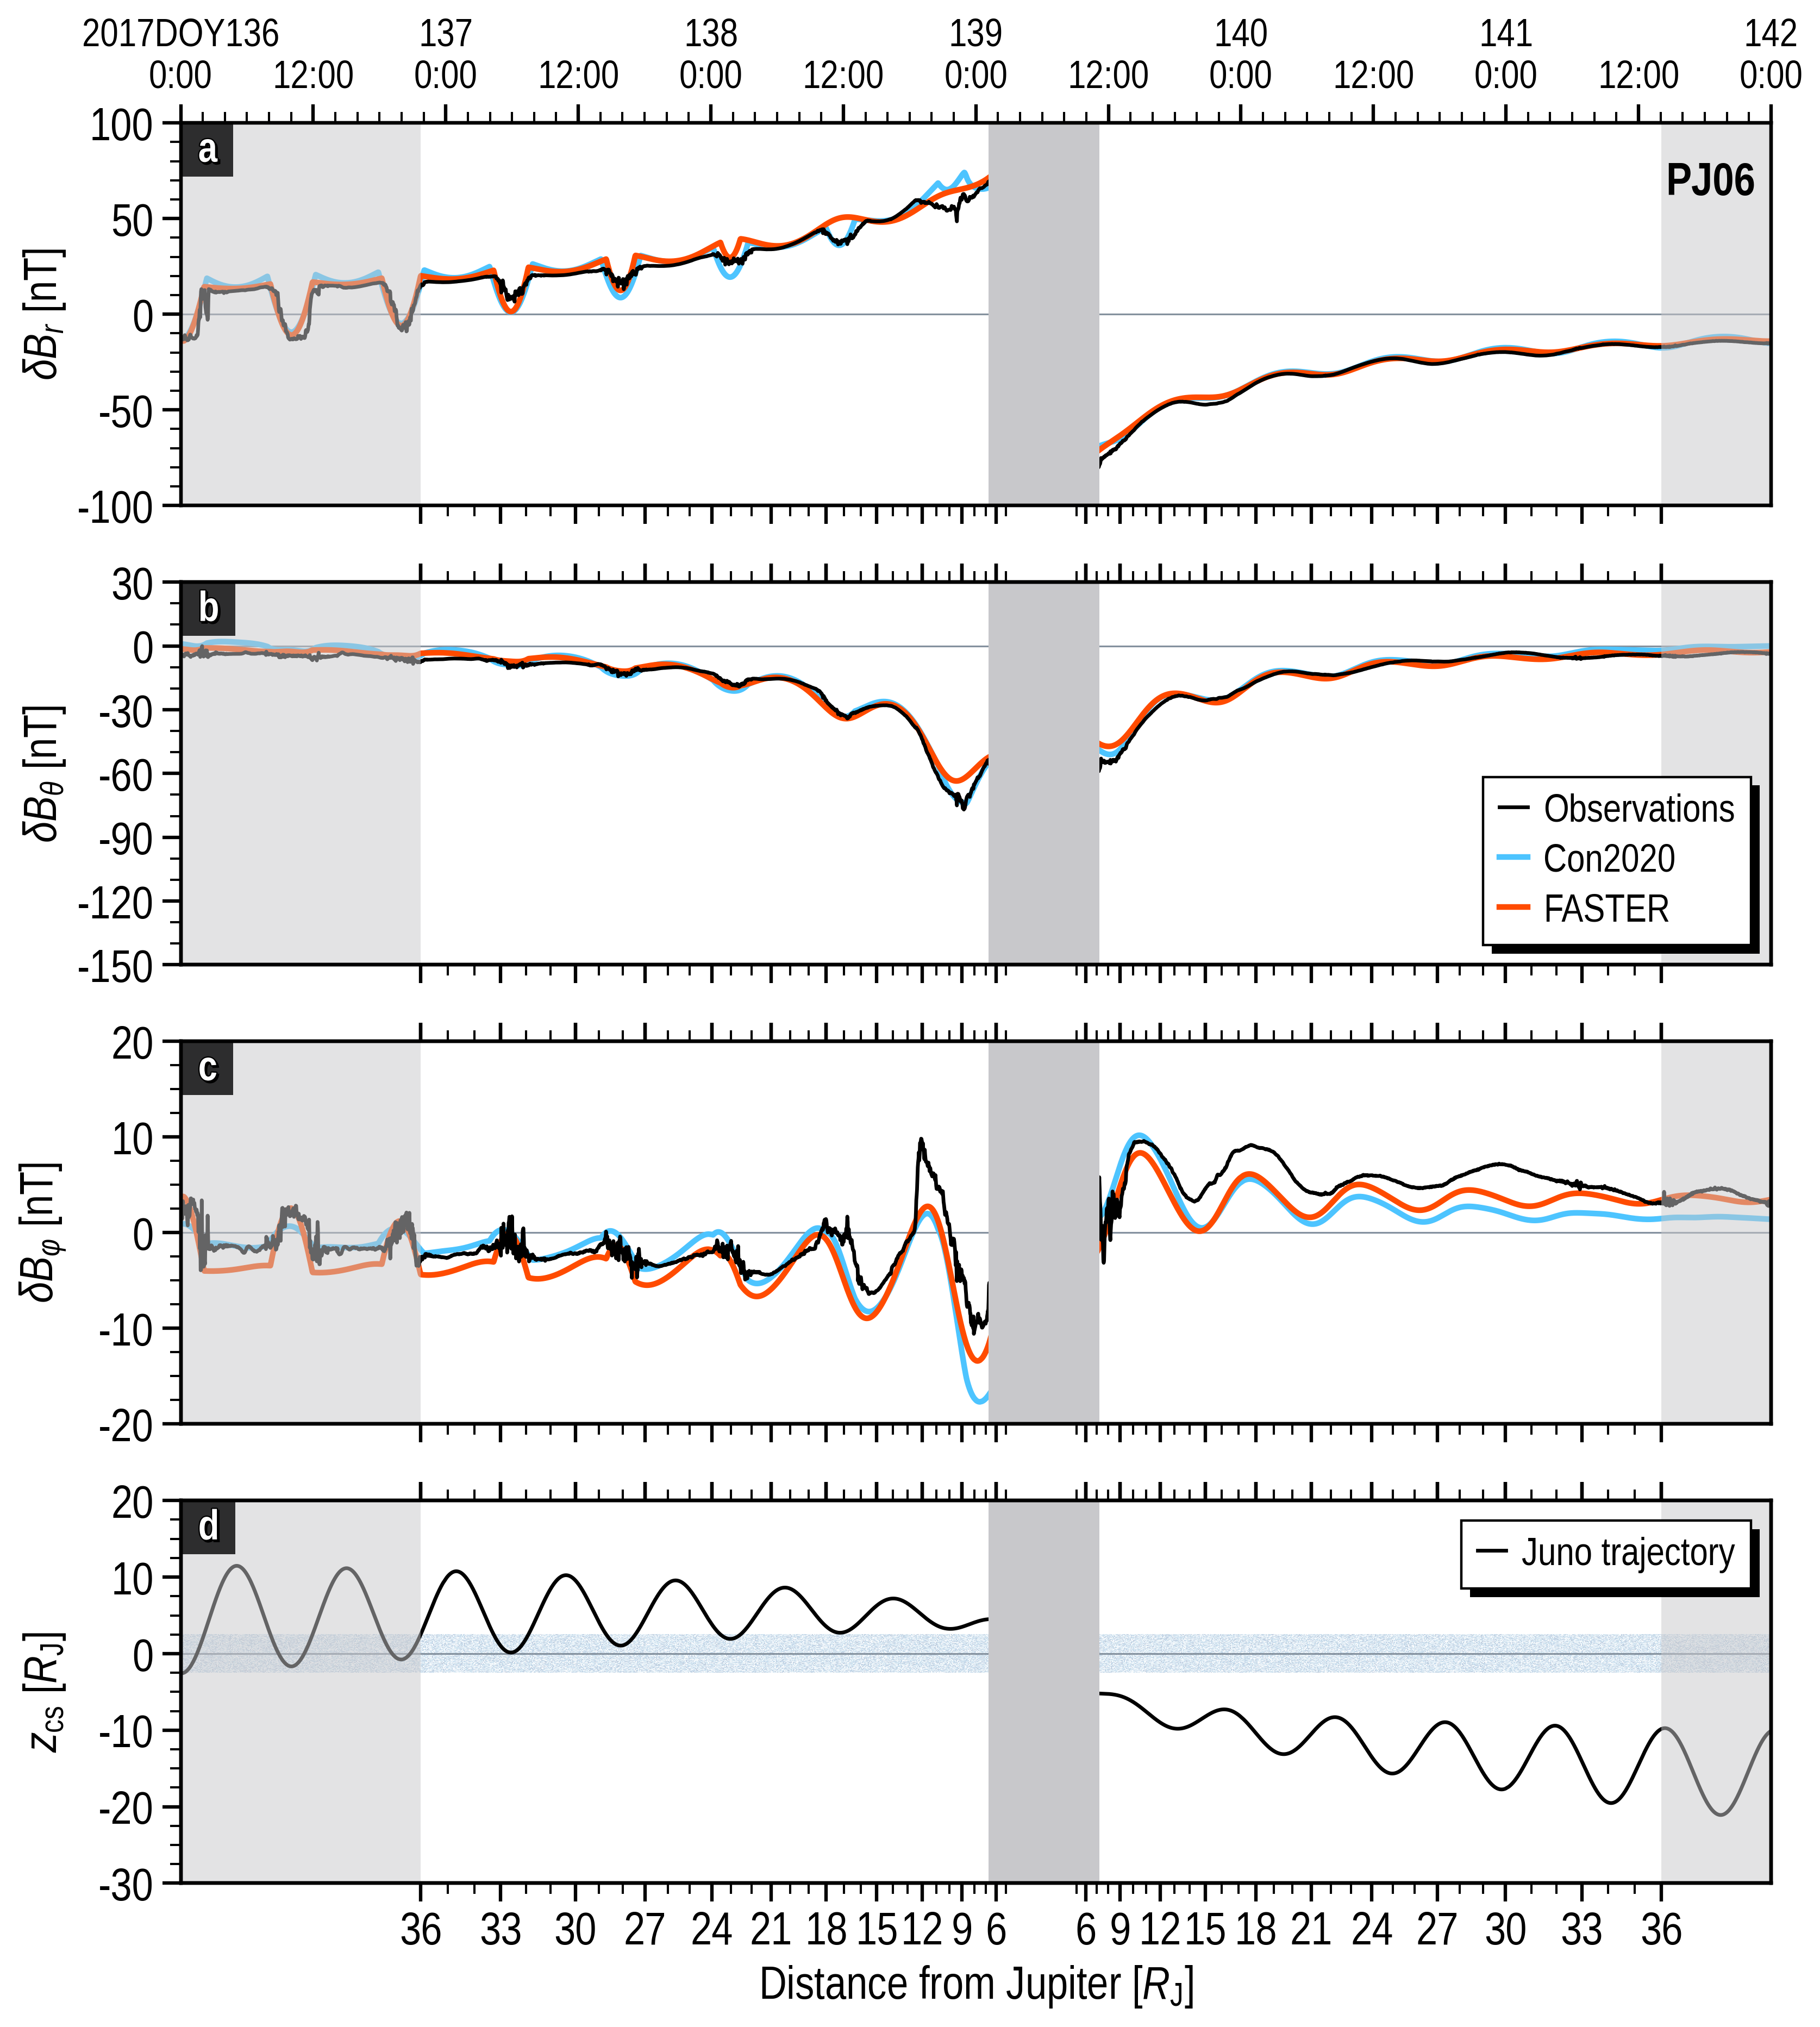

In [13]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

"""# カラーマップと中心色
cmap = plt.get_cmap("Blues")
base_color = cmap(0.7)

# 正規分布に従う粒状ノイズ
rng = np.random.default_rng(42)
noise = rng.normal(loc=0.5, scale=0.35, size=(500, 1200))
noise = np.clip(noise, 0, 1)

im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap=cmap,
    vmin=0,
    vmax=1,
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
    zorder=2,
)"""

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(136, 142)
timeax.set_xticks([136.0, 136.5, 137.0, 137.5, 138.0, 138.5,
                   139.0, 139.5, 140.0, 140.5,
                   141.0, 141.5, 142.0])
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '137\n0:00', '12:00',
                        '138\n0:00', '12:00', '139\n0:00', '12:00',
                        '140\n0:00', '12:00', '141\n0:00', '12:00',
                        '142\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b3_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')

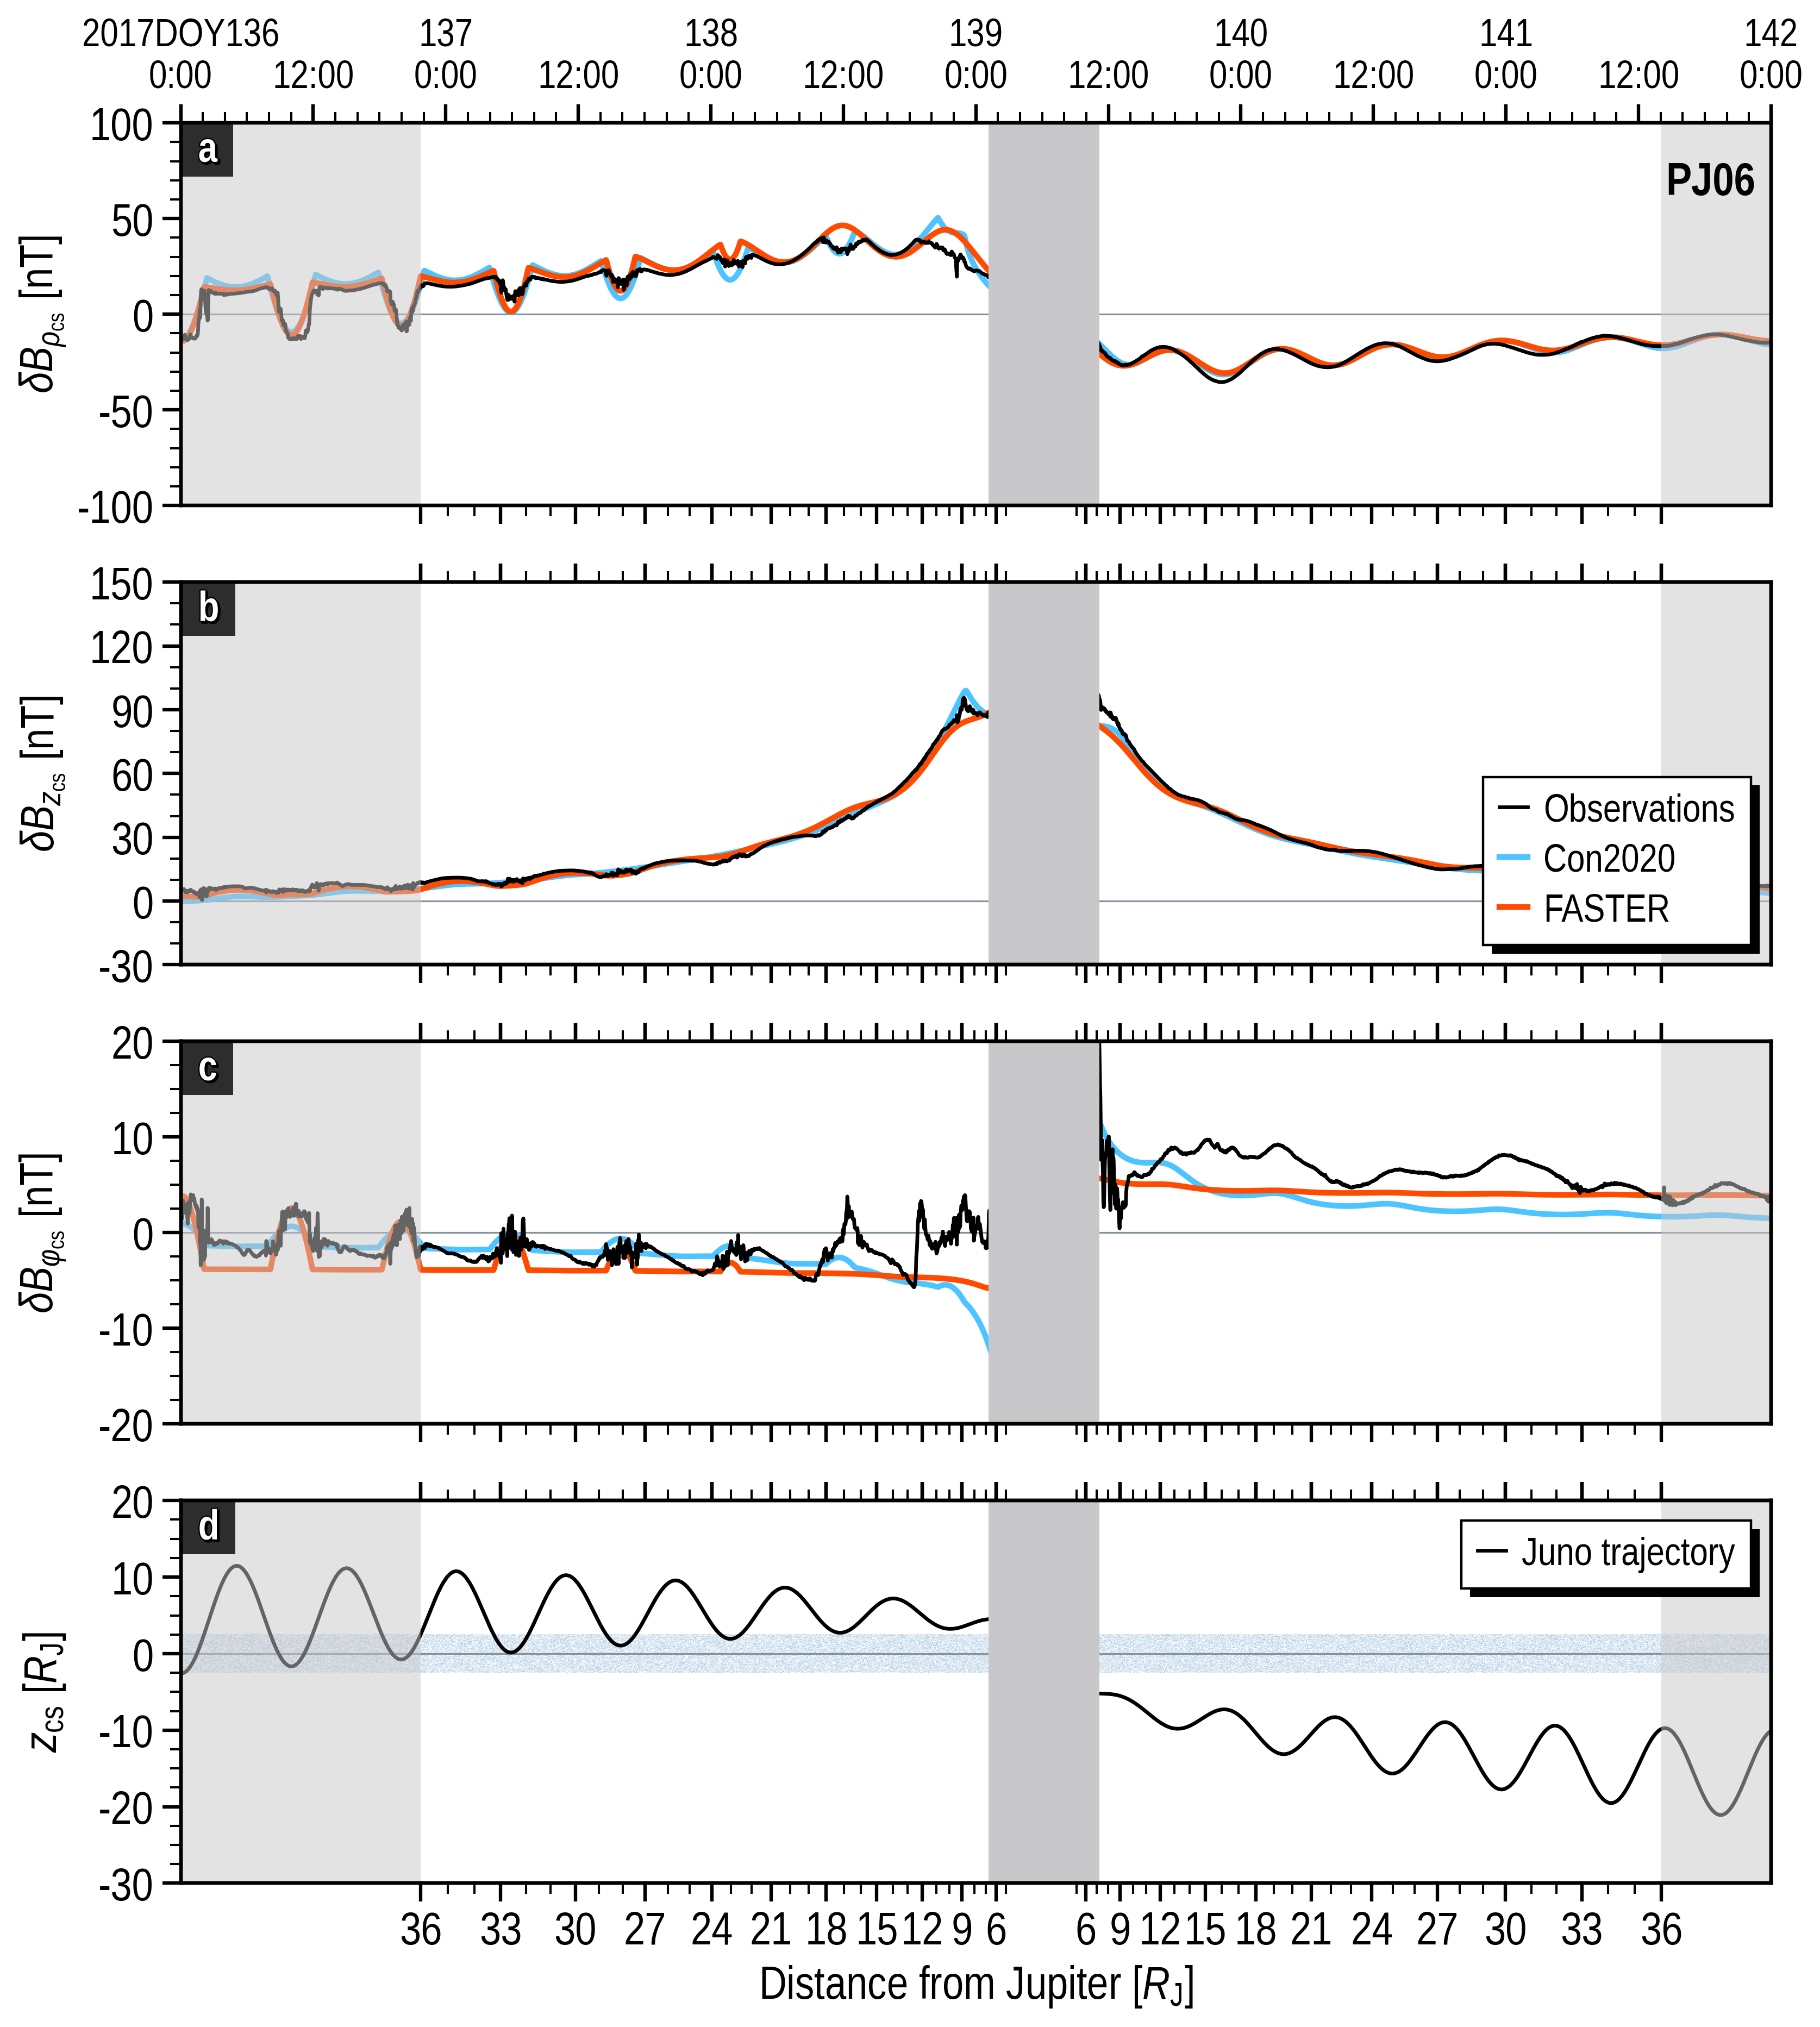

In [14]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{\rho_{\rm cs}}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{z_{\rm cs}}$ [nT]',
            min=-30, max=150,
            ticks=np.linspace(-30, 150, 7),
            ticklabels=np.linspace(-30, 150, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi_{\rm cs}}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBrho_cs, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBrho1_cs, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBrho2_cs, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)

F.ax[1].plot(time_arr, dBz_cs, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBz1_cs, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBz2_cs, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)

F.ax[2].plot(time_arr, dBphi_cs, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_cs, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_cs, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

"""# カラーマップと中心色
cmap = plt.get_cmap("Blues")
base_color = cmap(0.7)

# 正規分布に従う粒状ノイズ
rng = np.random.default_rng(42)
noise = rng.normal(loc=0.5, scale=0.35, size=(500, 1200))
noise = np.clip(noise, 0, 1)

im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap=cmap,
    vmin=0,
    vmax=1,
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
    zorder=2,
)"""

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(136, 142)
timeax.set_xticks([136.0, 136.5, 137.0, 137.5, 138.0, 138.5,
                   139.0, 139.5, 140.0, 140.5,
                   141.0, 141.5, 142.0])
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '137\n0:00', '12:00',
                        '138\n0:00', '12:00', '139\n0:00', '12:00',
                        '140\n0:00', '12:00', '141\n0:00', '12:00',
                        '142\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

# plt.savefig('img/compare_a0_a1_b3_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
#             bbox_inches='tight')

Text(0.02, 0.97, 'PJ06')

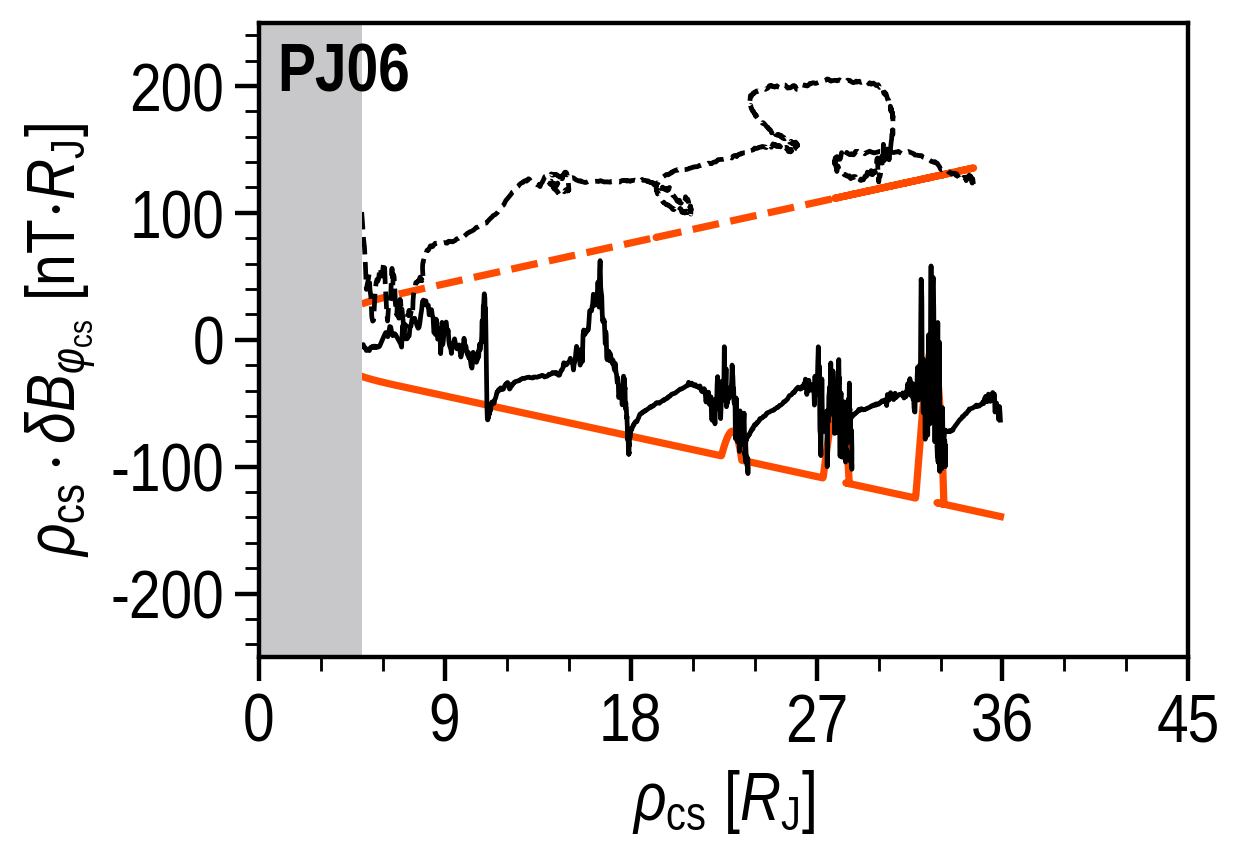

In [15]:
# ===========================================================
# Plot
# ===========================================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.5, 4), dpi='L')
F.initialize()

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0,
            max=45.0,
            ticks=np.arange(0, 45+1, 9),
            ticklabels=np.arange(0, 45+1, 9),
            minor_num=3)
F.set_yaxis(ax_idx=0,
            label=r'$\rho_{\rm cs}\cdot \delta B_{\varphi_{\rm cs}}$ [nT$\cdot R_{\rm J}$]',
            min=-250, max=250,
            ticks=np.linspace(-200, 200, 5),
            ticklabels=np.linspace(-200, 200, 5, dtype=int),
            minor_num=5)

# The plot
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
F.ax.plot(rho_cs[outer_idx[0]:inner_idx[0]],
          rho_cs[outer_idx[0]:inner_idx[0]] *
          dBphi_cs[outer_idx[0]:inner_idx[0]],
          color='k',
          linewidth=1.5, label='Observations', zorder=2.0)
F.ax.plot(rho_cs[inner_idx[-1]:outer_idx[-1]],
          rho_cs[inner_idx[-1]:outer_idx[-1]] *
          dBphi_cs[inner_idx[-1]:outer_idx[-1]],
          color='k', linestyle='--',
          linewidth=1.5, label='Observations', zorder=2.0)
F.ax.plot(rho_cs[outer_idx[0]:inner_idx[0]],
          rho_cs[outer_idx[0]:inner_idx[0]] *
          dBphi2_cs[outer_idx[0]:inner_idx[0]],
          color=UC.red,
          linewidth=2.3, label='FASTER', zorder=1.0)
F.ax.plot(rho_cs[inner_idx[-1]:outer_idx[-1]],
          rho_cs[inner_idx[-1]:outer_idx[-1]] *
          dBphi2_cs[inner_idx[-1]:outer_idx[-1]],
          color=UC.red, linestyle='--',
          linewidth=2.3, label='FASTER', zorder=1.0)

# Inner shades
F.ax.axvspan(0, 5.0,
             fc=UC.lightgray, ec=None, zorder=2.5)

F.ax.text(0.02, 0.97, 'PJ'+str(PJ_num).zfill(2),
          color='k',
          fontweight='bold',
          fontsize=F.fontsize,
          verticalalignment='top',
          horizontalalignment='left',
          transform=F.ax.transAxes)

# 全データ

In [103]:
PJ_num = 6

a_fit_result = []
b_fit_result = []
sig_a_fit_result = []
sig_b_fit_result = []
Juno_MLT_result = []
Juno_pj_result = []
in_out_result = []
RMSE_result = []

for i in range(len(PJ_list)):
    PJ_num = PJ_list[i]

    dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
    time_arr = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
    Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
    By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
    Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
    rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
    ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
    rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
    JunoMLT = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

    rx_pc *= 1/71492.0  # [RJ]
    ry_pc *= 1/71492.0  # [RJ]
    rz_pc *= 1/71492.0  # [RJ]

    # 座標
    r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
    cos_phi = rx_pc/r_pc
    sin_phi = ry_pc/r_pc
    cos_theta = rz_pc/r_pc
    sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
    # print('Distance [RJ]:', r_pc[0], r_pc[-1])

    # ===========================================================
    # Internal field
    # ===========================================================
    Bx0_pc = np.zeros(time_arr.size)
    By0_pc = np.zeros(time_arr.size)
    Bz0_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                            ry_pc[i],
                                                            rz_pc[i])  # [nT]
    dBx = Bx_pc - Bx0_pc
    dBy = By_pc - By0_pc
    dBz = Bz_pc - Bz0_pc
    dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
    dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
    dBphi = -dBx*sin_phi + dBy*cos_phi

    # ===========================================================
    # DoE model
    # ===========================================================
    csfield = CSField()

    select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
    # print(f0[select_pj, 1], f0[select_pj, 3])

    dBx2_pc = np.zeros(time_arr.size)
    dBy2_pc = np.zeros(time_arr.size)
    dBz2_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        csfield.config(
            i_phi0=f0[select_pj, 1],
            I_rho0=f0[select_pj, 3],
            a0=2.19129985E-6,
            MLT0=2.46607518,
            a1=-5.12302579,
            MLT1=-16.93107288,
            b1=3.64,
        )
        dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                    ry_pc[i],
                                                                    rz_pc[i],
                                                                    JunoMLT[i])  # [T]

    x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    dBx2_pc *= 1E+9    # [nT]
    dBy2_pc *= 1E+9    # [nT]
    dBz2_pc *= 1E+9    # [nT]
    dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
        sin_theta*sin_phi + dBz2_pc*cos_theta
    dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
        dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
    dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

    # ===========================================================
    # RMSE（Root Mean Squared Error）
    # ===========================================================
    x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    in_30rj = np.where(r_pc < 36.0)[0][0]
    out_30rj = np.where(r_pc < 36.0)[0][-1]
    if PJ_num in [17]:
        in_5rj = np.where(rho_cs < 8.0)[0][0]
        out_5rj = np.where(rho_cs < 8.0)[0][-1]
    else:
        in_5rj = np.where(rho_cs < 5.0)[0][0]
        out_5rj = np.where(rho_cs < 5.0)[0][-1]
    in_num = in_5rj-in_30rj-1
    out_num = out_30rj-out_5rj-1

    # ===========================================================
    # Sys3 (x, y, z) -> CS (rho, phi, z)
    # ===========================================================
    dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
    dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
    dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

    dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
    dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
    dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

    # ===========================================================
    # Total RMSE
    # ===========================================================
    RMS_toroidal_cs_inb = math.sqrt(
        (
            np.sum(
                (dBphi_cs[in_30rj:in_5rj]-dBphi2_cs[in_30rj:in_5rj])**2
            )
        )/(in_num)
    )
    RMS_toroidal_cs_outb = math.sqrt(
        (
            np.sum(
                (dBphi_cs[out_5rj:out_30rj]-dBphi2_cs[out_5rj:out_30rj])**2
            )
        )/(out_num)
    )
    print('RMSE (FASTER) [nT]:', round(RMS_toroidal_cs_inb, 2),
          round(RMS_toroidal_cs_outb, 2))

    # ===========================================================
    # Plot boundary
    # ===========================================================
    if PJ_num in [17]:
        r_ticks_ref = np.arange(8.0, 36.0+1, 1)
    else:
        r_ticks_ref = np.arange(5.0, 36.0+1, 1)
    r_ticks = np.zeros((r_ticks_ref.size*2, 2))
    for i in range(r_ticks_ref.size):
        r_i = r_ticks_ref[-1]-i
        time_i = time_arr[np.where(r_pc < r_i)[0][0]]
        r_ticks[i, 0] = r_i
        r_ticks[i, 1] = time_i

        time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
        r_ticks[-i-1, 0] = r_i
        r_ticks[-i-1, 1] = time_i

    # ===========================================================
    # Plot
    # ===========================================================
    F = ShareXaxis()
    F.fontsize = 22
    F.fontname = 'Liberation Sans Narrow'

    F.set_figparams(nrows=2, figsize=(6.2, 6.5), dpi='L')
    F.initialize()

    F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
                min=-45.0,
                max=45.0,
                ticks=np.arange(-45, 45+1, 9),
                ticklabels=np.abs(np.arange(-45, 45+1, 9)),
                minor_num=3)
    F.set_yaxis(ax_idx=0,
                label=r'$(1/f_z)\cdot \rho_{\rm cs}\cdot \delta B_{\varphi_{\rm cs}}$ [nT$\cdot R_{\rm J}$]',
                min=-300, max=300,
                ticks=np.linspace(-300, 300, 7),
                ticklabels=np.linspace(-300, 300, 7, dtype=int),
                minor_num=10)
    F.set_yaxis(ax_idx=1,
                label=r'MLT [hour]',
                min=0, max=24,
                ticks=np.arange(0, 24, 4),
                ticklabels=np.arange(0, 24, 4, dtype=int),
                minor_num=4)

    # The plot
    inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
    outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]

    rho_cs_inb = rho_cs[in_30rj:in_5rj]
    z_cs_inb = z_cs[in_30rj:in_5rj]
    dBphi_cs_inb = dBphi_cs[in_30rj:in_5rj]
    dBphi2_cs_inb = dBphi2_cs[in_30rj:in_5rj]
    JunoMLT_inb = JunoMLT[in_30rj:in_5rj]
    rho_cs_outb = rho_cs[out_5rj:out_30rj]
    z_cs_outb = z_cs[out_5rj:out_30rj]
    dBphi_cs_outb = dBphi_cs[out_5rj:out_30rj]
    dBphi2_cs_outb = dBphi2_cs[out_5rj:out_30rj]
    JunoMLT_outb = JunoMLT[out_5rj:out_30rj]

    # INBOUND OBSERVATIONS
    g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
    f_z = -np.sign(z_cs_inb)*g_rho
    f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, -g_rho*z_cs_inb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    y_obs = (1/f_z)*rho_cs_inb*dBphi_cs_inb
    F.ax[0].plot(-rho_cs_inb,
                 y_obs,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[0].plot(-rho_cs_inb,
                 (1/f_z)*rho_cs_inb*dBphi2_cs_inb,
                 color=UC.red,
                 linewidth=1.8, label='FASTER', zorder=1.0)

    # INBOUND weighted linear fit
    g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
    f_z = -np.sign(z_cs_inb)*g_rho
    f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, -g_rho*z_cs_inb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    a, b, sigma_a, sigma_b = weighted_linear_fit(
        rho_cs_inb*RJ,
        (1/f_z)*(rho_cs_inb*RJ)*(dBphi_cs_inb*1E-9),
        np.abs(f_z))
    a_fit_result += [a]             # beta [T]
    b_fit_result += [b]             # alpha [T m]
    sig_a_fit_result += [sigma_a]   # beta [T]
    sig_b_fit_result += [sigma_b]   # alpha [T m]
    Juno_MLT_result += [JunoMLT_inb[0]]
    in_out_result += [1]
    Juno_pj_result += [PJ_num]
    RMSE_result += [math.sqrt(
        np.sum((y_obs-(a*rho_cs_inb*RJ+b)*1E+9/RJ)**2)/in_num
    )]
    F.ax[0].plot(-rho_cs_inb,
                 (a*rho_cs_inb*RJ+b)*1E+9/RJ,
                 color=UC.blue,
                 linewidth=1.8, label='Weighted', zorder=1.0)

    # OUTBOUND OBSERVATIONS
    g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
    f_z = -np.sign(z_cs_outb)*g_rho
    f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, -g_rho*z_cs_outb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    y_obs = (1/f_z)*rho_cs_outb*dBphi_cs_outb
    F.ax[0].plot(rho_cs_outb,
                 y_obs,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[0].plot(rho_cs_outb,
                 (1/f_z)*rho_cs_outb*dBphi2_cs_outb,
                 color=UC.red,
                 linewidth=1.8, label='FASTER', zorder=1.0)

    # OUTBOUND weighted linear fit
    if rho_cs_outb.size > 4:
        g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
        f_z = -np.sign(z_cs_outb)*g_rho
        f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, -g_rho*z_cs_outb/2.5)
        eps = 1e-6
        f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
        a, b, sigma_a, sigma_b = weighted_linear_fit(
            rho_cs_outb*RJ,
            (1/f_z)*(rho_cs_outb*RJ)*(dBphi_cs_outb*1E-9),
            np.abs(f_z))
        a_fit_result += [a]             # beta [T]
        b_fit_result += [b]             # alpha [T m]
        sig_a_fit_result += [sigma_a]   # beta [T]
        sig_b_fit_result += [sigma_b]   # alpha [T m]
        Juno_MLT_result += [JunoMLT_outb[-1]]
        in_out_result += [-1]
        Juno_pj_result += [PJ_num]
        RMSE_result += [math.sqrt(
            np.sum((y_obs-(a*rho_cs_outb*RJ+b)*1E+9/RJ)**2)/out_num
        )]
        F.ax[0].plot(rho_cs_outb,
                     (a*rho_cs_outb*RJ+b)*1E+9/RJ,
                     color=UC.blue,
                     linewidth=1.8, label='Weighted', zorder=1.0)

    # MLT
    F.ax[1].plot(-rho_cs_inb,
                 JunoMLT_inb,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[1].plot(rho_cs_outb,
                 JunoMLT_outb,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    # Inner shades
    for j in range(2):
        F.ax[j].axvspan(-5.0, 5.0,
                        fc=UC.lightgray, ec=None, zorder=2.5)

    F.ax[0].text(0.09, 0.97, 'PJ'+str(PJ_num).zfill(2),
                 color='k',
                 fontweight='bold',
                 fontsize=F.fontsize,
                 verticalalignment='top',
                 horizontalalignment='left',
                 transform=F.ax[0].transAxes)
    F.ax[0].text(0.02, 0.02, 'Inbound',
                 color='k',
                 fontsize=F.fontsize,
                 verticalalignment='bottom',
                 horizontalalignment='left',
                 transform=F.ax[0].transAxes)
    F.ax[0].text(0.98, 0.02, 'Outbound',
                 color='k',
                 fontsize=F.fontsize,
                 verticalalignment='bottom',
                 horizontalalignment='right',
                 transform=F.ax[0].transAxes)

    plt.savefig('img/B_cs_2components/PJ'+str(PJ_num).zfill(2)+'.png',
                bbox_inches='tight')

    plt.close()

RMSE (FASTER) [nT]: 5.4 4.42
RMSE (FASTER) [nT]: 2.19 1.3
RMSE (FASTER) [nT]: 1.42 1.23
RMSE (FASTER) [nT]: 1.99 1.49
RMSE (FASTER) [nT]: 2.64 2.78
RMSE (FASTER) [nT]: 2.73 1.17
RMSE (FASTER) [nT]: 2.9 0.62
RMSE (FASTER) [nT]: 3.54 2.37
RMSE (FASTER) [nT]: 3.94 2.85
RMSE (FASTER) [nT]: 2.26 2.72
RMSE (FASTER) [nT]: 3.82 3.04
RMSE (FASTER) [nT]: 3.29 0.87
RMSE (FASTER) [nT]: 1.84 1.24
RMSE (FASTER) [nT]: 2.72 1.78
RMSE (FASTER) [nT]: 2.52 0.68
RMSE (FASTER) [nT]: 1.85 0.98
RMSE (FASTER) [nT]: 1.91 1.42
RMSE (FASTER) [nT]: 1.46 0.82
RMSE (FASTER) [nT]: 2.12 0.74
RMSE (FASTER) [nT]: 2.74 1.98
RMSE (FASTER) [nT]: 5.35 1.83
RMSE (FASTER) [nT]: 3.15 1.04
RMSE (FASTER) [nT]: 4.26 1.05
RMSE (FASTER) [nT]: 3.32 1.34
RMSE (FASTER) [nT]: 2.0 0.59
RMSE (FASTER) [nT]: 3.62 1.11
RMSE (FASTER) [nT]: 6.28 1.32
RMSE (FASTER) [nT]: 2.14 0.67
RMSE (FASTER) [nT]: 3.92 0.59
RMSE (FASTER) [nT]: 3.23 1.17
RMSE (FASTER) [nT]: 5.14 1.06
RMSE (FASTER) [nT]: 7.13 1.95
RMSE (FASTER) [nT]: 11.63 1.9
RMSE (FASTER) 

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_10188/383378158.py:81: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_beta_out, pcov = curve_fit(func, Juno_MLT_out, beta_out)


Best fit for beta_out*1E+9 [nT]:
1.0 4.2518 -0.2086


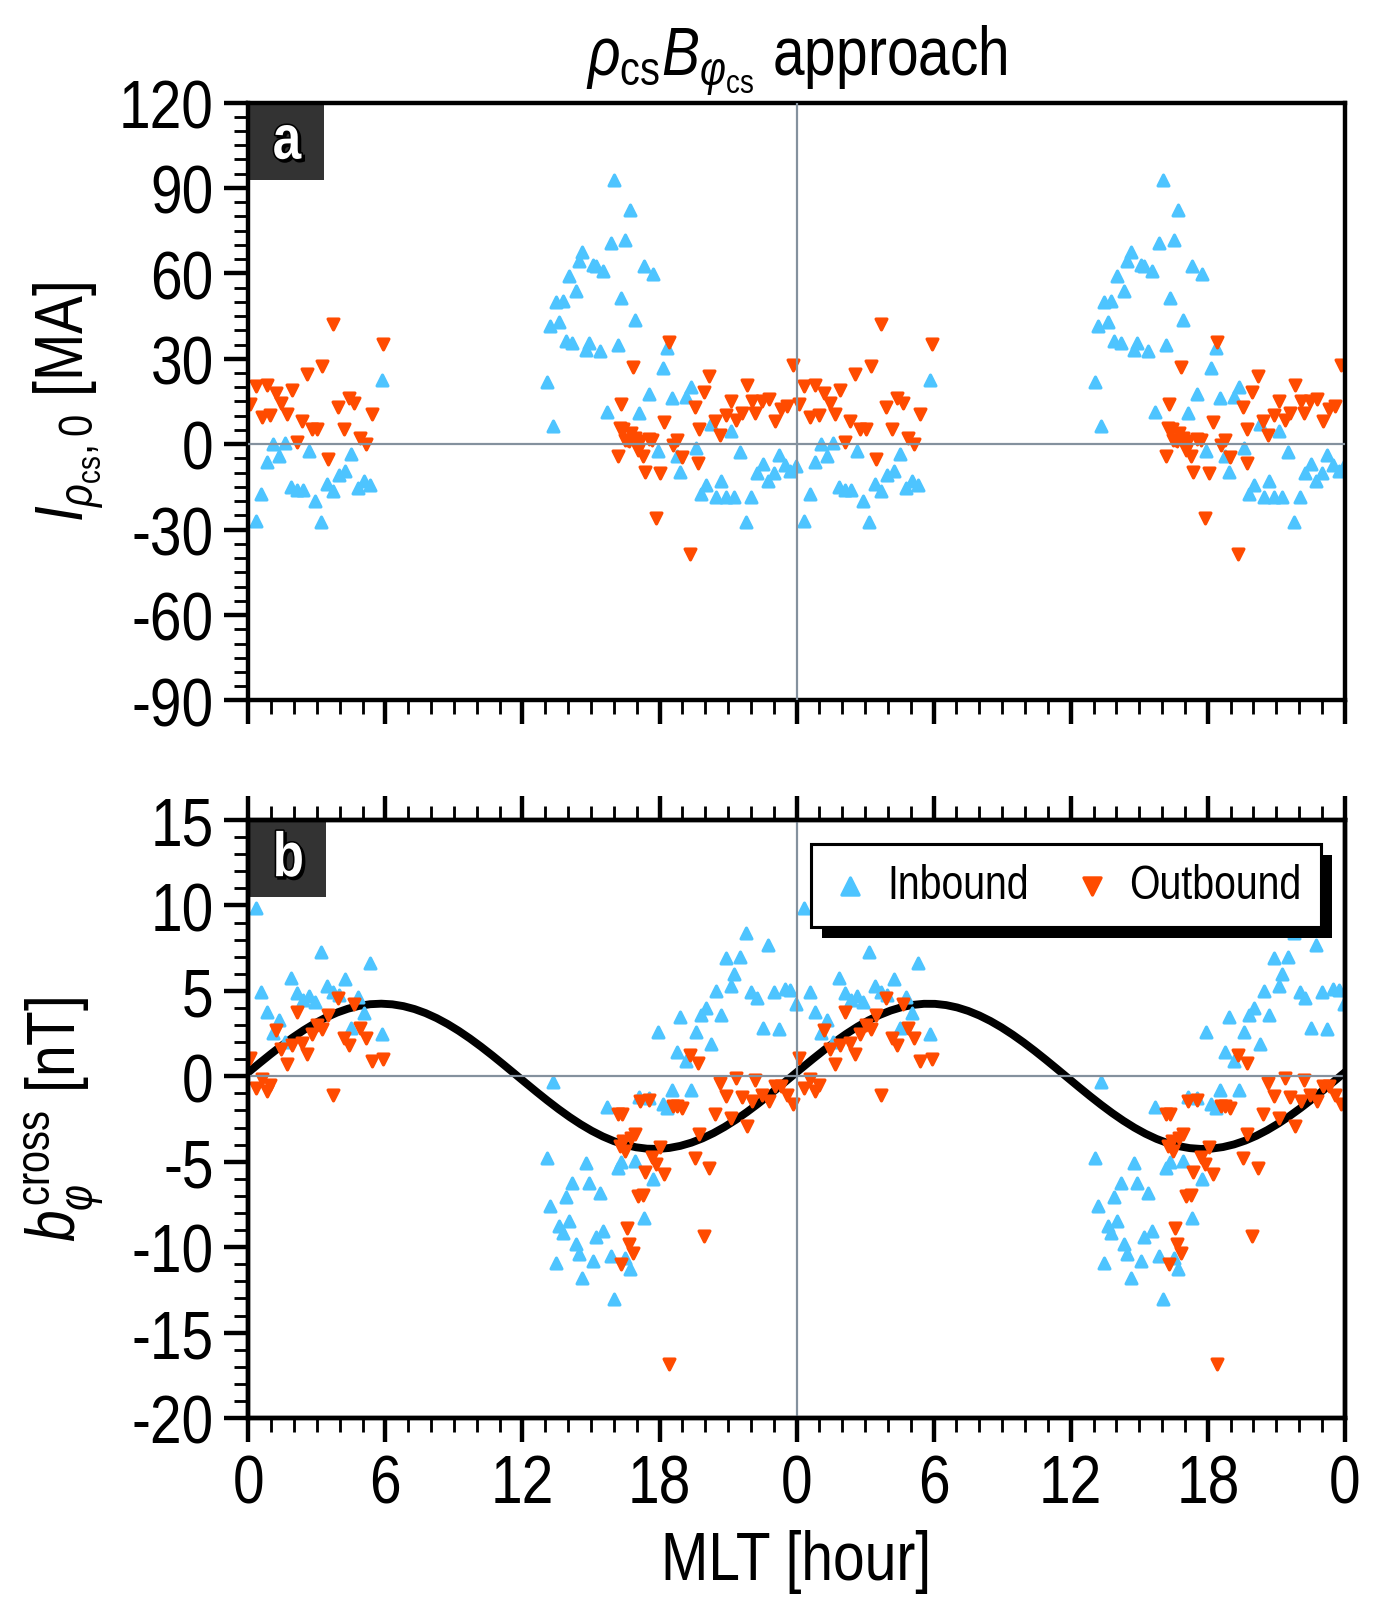

In [104]:
def func(X, a0, a1, a2):  # 2次式近似
    """
    Args:
        X (_type_): MLT [hr]
        a0 (_type_): _description_
        a1 (_type_): _description_
        a2 (_type_): _description_
    """
    MLT_rad = 2*np.pi*(X-a2)/24.0
    Y = 0 + a1*np.sin(MLT_rad)
    return Y


F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.2, 7), dpi='L')
F.hspace = 0.2
F.initialize()

F.set_xaxis(label=r'MLT [hour]',
            min=0.0,
            max=48.0,
            ticks=np.arange(0, 48+1, 6),
            ticklabels=np.mod(np.arange(0, 48+1, 6), 24),
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$I_{\rho_{\rm cs},0}$ [MA]',
            min=-90, max=120,
            ticks=np.linspace(-90, 120, 8),
            ticklabels=np.linspace(-90, 120, 8, dtype=int),
            minor_num=6)
F.set_yaxis(ax_idx=1,
            label=r'$b_{\varphi}^{\rm cross}$ [nT]',
            min=-20, max=15,
            ticks=np.linspace(-20, 15, 8),
            ticklabels=np.linspace(-20, 15, 8, dtype=int),
            minor_num=5)

alpha_in = []
alpha_out = []
beta_in = []
beta_out = []
Juno_MLT_in = []
Juno_MLT_out = []
for i in range(len(in_out_result)):
    if in_out_result[i] > 0:
        alpha_in += [b_fit_result[i]]        # [T m]
        beta_in += [a_fit_result[i]]         # [T]
        Juno_MLT_in += [Juno_MLT_result[i]]  # [hour]
    elif in_out_result[i] < 0:
        alpha_out += [b_fit_result[i]]        # [T m]
        beta_out += [a_fit_result[i]]         # [T]
        Juno_MLT_out += [Juno_MLT_result[i]]  # [hour]

alpha_in = np.array(alpha_in)
alpha_out = np.array(alpha_out)
beta_in = np.array(beta_in)
beta_out = np.array(beta_out)
Juno_MLT_in = np.array(Juno_MLT_in)
Juno_MLT_out = np.array(Juno_MLT_out)

for i in range(2):
    F.ax[0].scatter(Juno_MLT_in+24*i,
                    (alpha_in*2*np.pi/MU0)*1E-6,
                    c=UC.lightblue, marker='^', s=12)
    F.ax[0].scatter(Juno_MLT_out+24*i,
                    (alpha_out*2*np.pi/MU0)*1E-6,
                    c=UC.red, marker='v', s=12)
    F.ax[1].scatter(Juno_MLT_in+24*i,
                    beta_in*1E+9,
                    c=UC.lightblue, marker='^', s=12)
    F.ax[1].scatter(Juno_MLT_out+24*i,
                    beta_out*1E+9,
                    c=UC.red, marker='v', s=12)

# OUTBOUND: betaを三角関数でフィッティング
beta_out = beta_out[np.argsort(Juno_MLT_out)]*1E+9
Juno_MLT_out = np.sort(Juno_MLT_out)
popt_beta_out, pcov = curve_fit(func, Juno_MLT_out, beta_out)
MLT_arr = np.linspace(0.0, 48.0, 100)
beta_out_fit = func(MLT_arr,
                    popt_beta_out[0],
                    popt_beta_out[1],
                    popt_beta_out[2])
F.ax[1].plot(MLT_arr, beta_out_fit, color='k',
             linewidth=2.5, zorder=0.9)
print('Best fit for beta_out*1E+9 [nT]:')
print(round(popt_beta_out[0], 5),
      round(popt_beta_out[1], 5),
      round(popt_beta_out[2], 5))

# Dummy
F.ax[1].scatter(500, 500, c=UC.lightblue,
                marker='^', s=30, label='Inbound')
F.ax[1].scatter(500, 500, c=UC.red,
                marker='v', s=30, label='Outbound')

# Legend
legend = F.legend(ax_idx=1,
                  ncol=2, markerscale=1.0,
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.69,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)

for i in range(2):
    F.ax[i].axvline(x=24.0, color=UC.gray, linewidth=0.7, zorder=5)
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=5)

F.ax[0].set_title(
    r'$\rho_{\rm cs}B_{\varphi_{\rm cs}}$ approach')

plt.savefig('img/linear_fit_Bphi_2components.png',
            bbox_inches='tight')

Text(0.5, 1.0, '$\\rho_{\\rm cs}B_{\\varphi_{\\rm cs}}$ approach')

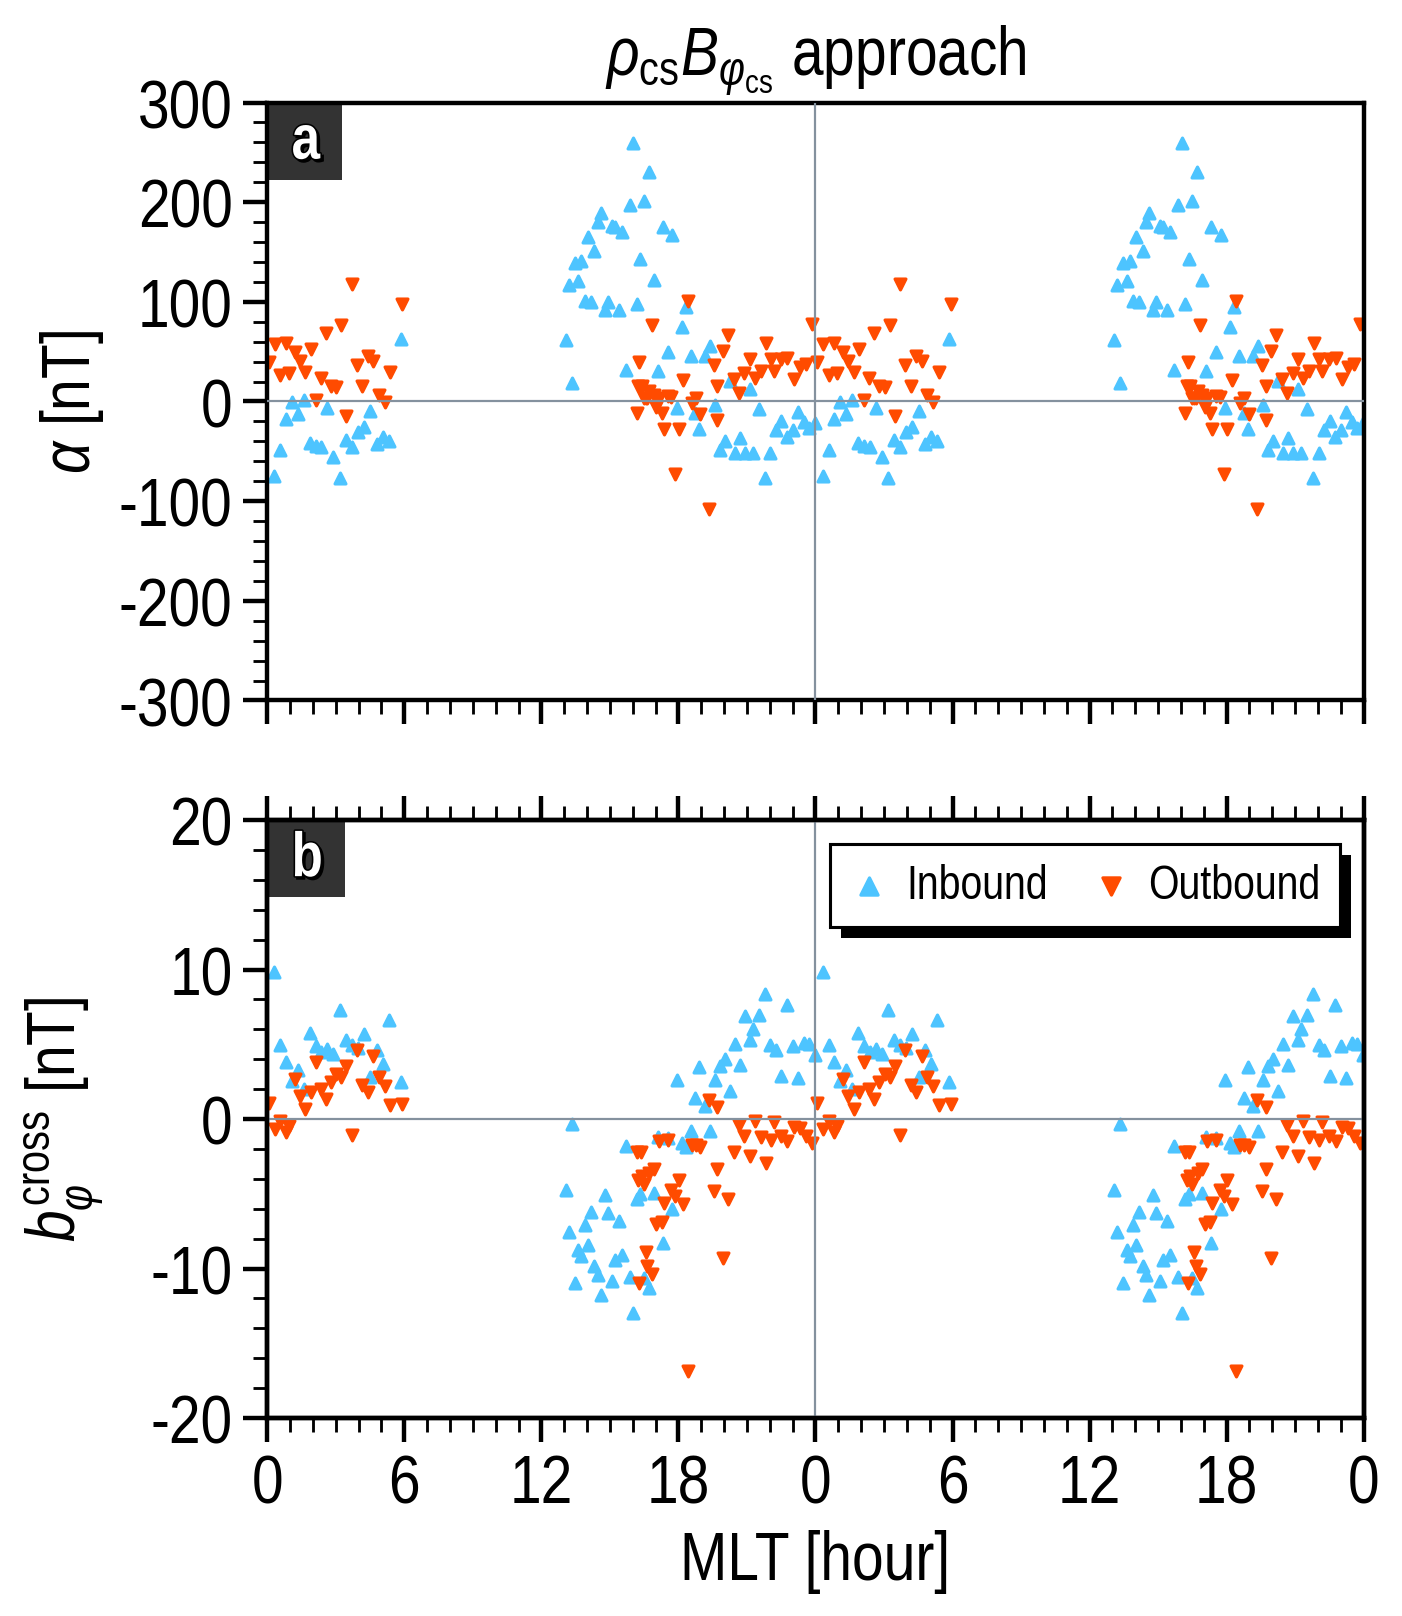

In [105]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.2, 7), dpi='L')
F.hspace = 0.2
F.initialize()

F.set_xaxis(label=r'MLT [hour]',
            min=0.0,
            max=48.0,
            ticks=np.arange(0, 48+1, 6),
            ticklabels=np.mod(np.arange(0, 48+1, 6), 24),
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$\alpha$ [nT]',
            min=-300, max=300,
            ticks=np.linspace(-300, 300, 7),
            ticklabels=np.linspace(-300, 300, 7, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$b_{\varphi}^{\rm cross}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=5)

alpha_in = []
alpha_out = []
beta_in = []
beta_out = []
Juno_MLT_in = []
Juno_MLT_out = []
for i in range(len(in_out_result)):
    if in_out_result[i] > 0:
        alpha_in += [b_fit_result[i]]        # [T m]
        beta_in += [a_fit_result[i]]         # [T]
        Juno_MLT_in += [Juno_MLT_result[i]]  # [hour]
    elif in_out_result[i] < 0:
        alpha_out += [b_fit_result[i]]        # [T m]
        beta_out += [a_fit_result[i]]         # [T]
        Juno_MLT_out += [Juno_MLT_result[i]]  # [hour]

alpha_in = np.array(alpha_in)
alpha_out = np.array(alpha_out)
beta_in = np.array(beta_in)
beta_out = np.array(beta_out)
Juno_MLT_in = np.array(Juno_MLT_in)
Juno_MLT_out = np.array(Juno_MLT_out)

for i in range(2):
    F.ax[0].scatter(Juno_MLT_in+24*i,
                    alpha_in*1E+9/RJ,
                    c=UC.lightblue,
                    marker='^', s=12)
    F.ax[0].scatter(Juno_MLT_out+24*i,
                    alpha_out*1E+9/RJ,
                    c=UC.red,
                    marker='v', s=12)
    F.ax[1].scatter(Juno_MLT_in+24*i,
                    beta_in*1E+9,
                    c=UC.lightblue,
                    marker='^', s=12)
    F.ax[1].scatter(Juno_MLT_out+24*i,
                    beta_out*1E+9,
                    c=UC.red,
                    marker='v', s=12)

# Dummy
F.ax[1].scatter(500, 500, c=UC.lightblue,
                marker='^', s=30, label='Inbound')
F.ax[1].scatter(500, 500, c=UC.red,
                marker='v', s=30, label='Outbound')

legend = F.legend(ax_idx=1,
                  ncol=2, markerscale=1.0,
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.69,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)

for i in range(2):
    F.ax[i].axvline(x=24.0, color=UC.gray, linewidth=0.7, zorder=5)
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=5)

F.ax[0].set_title(
    r'$\rho_{\rm cs}B_{\varphi_{\rm cs}}$ approach')

# plt.savefig('img/linear_fit_Bphi_2components.png',
#             bbox_inches='tight')

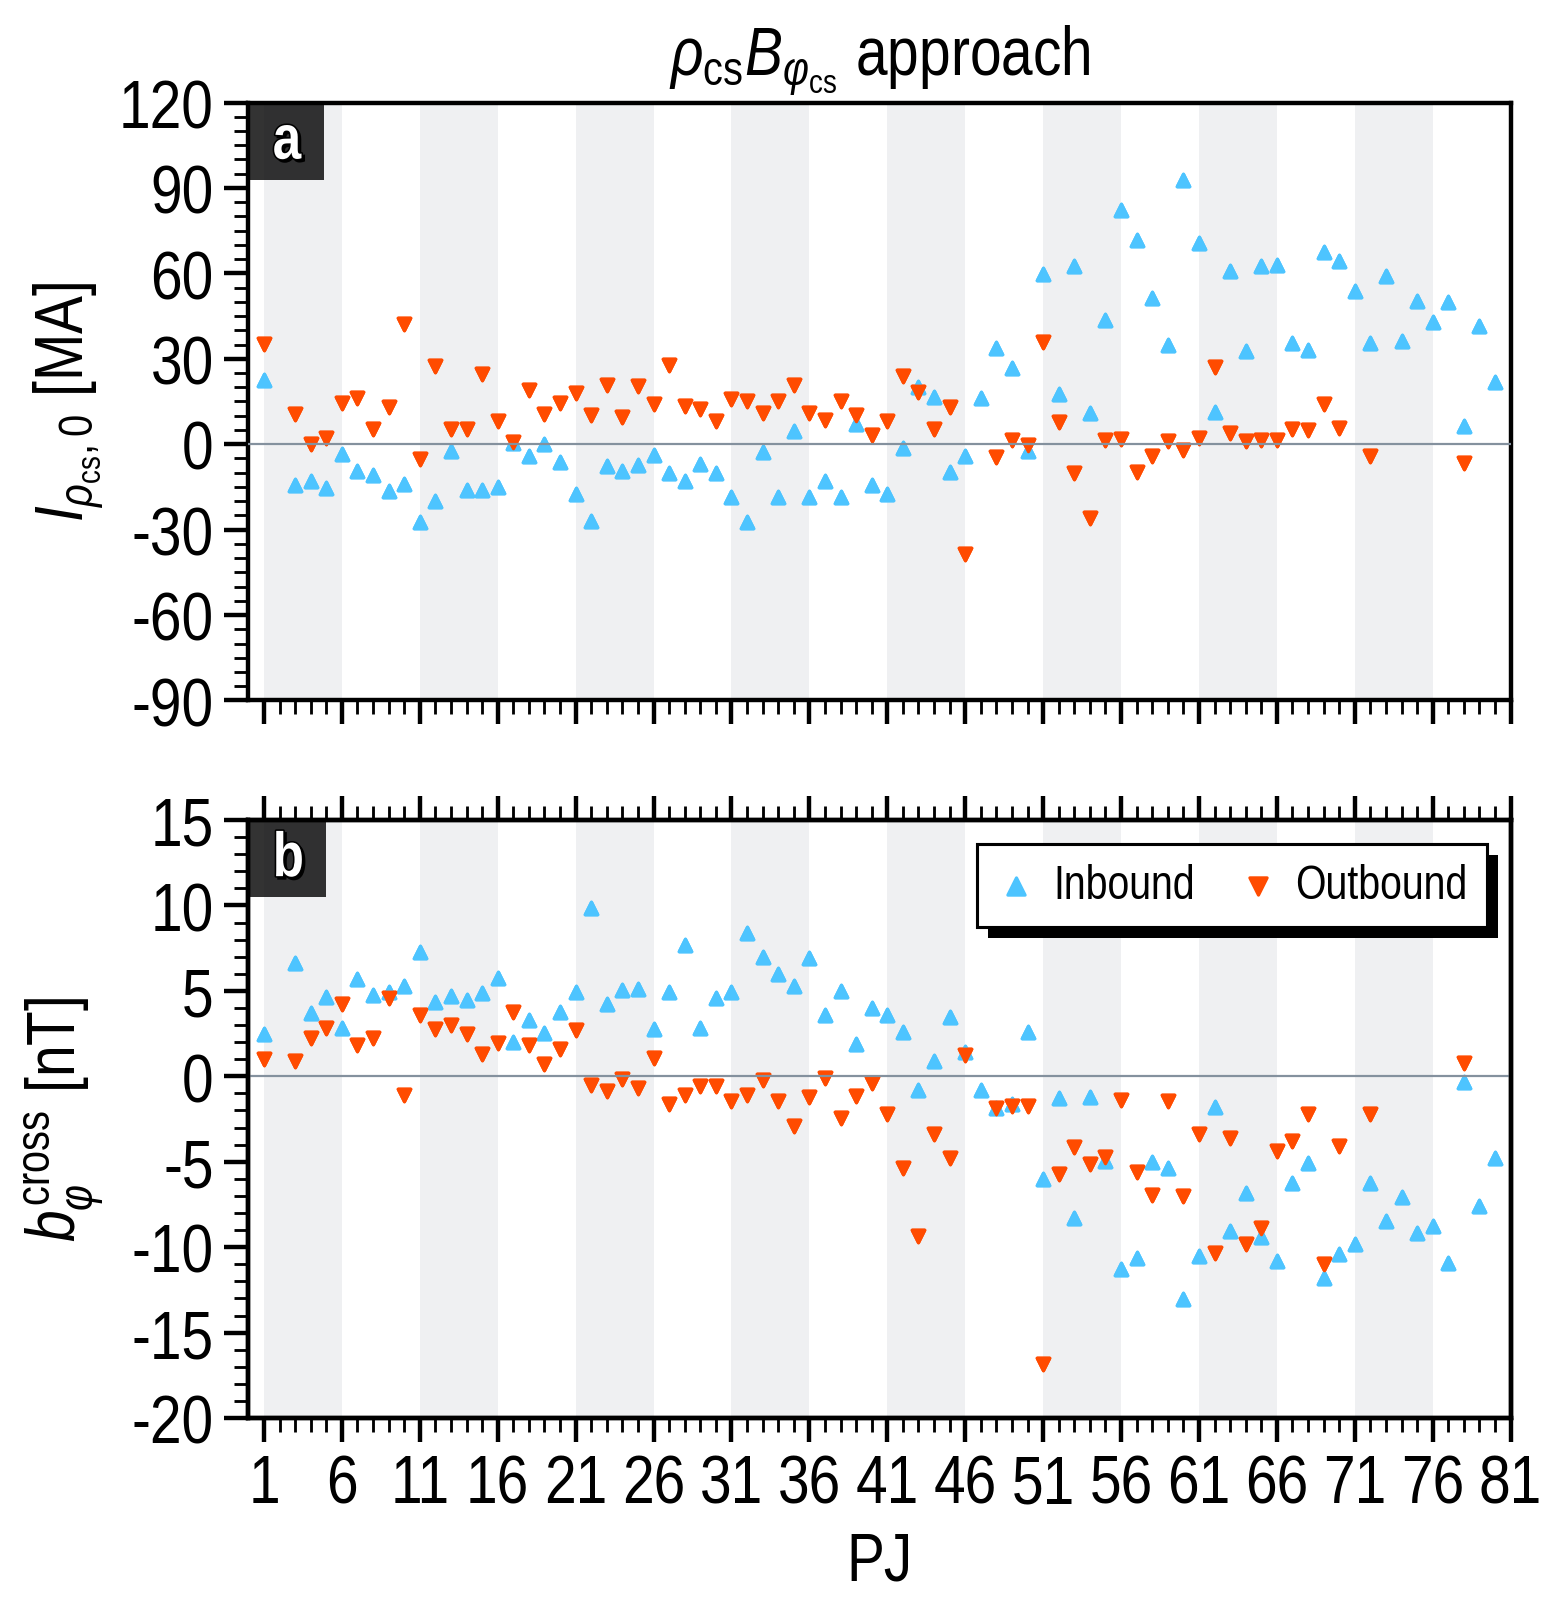

In [106]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(7, 7), dpi='L')
F.hspace = 0.2
F.initialize()

F.set_xaxis(label=r'PJ',
            min=0.0,
            max=81.0,
            ticks=np.arange(1, 81+1, 5),
            ticklabels=np.arange(1, 81+1, 5, int),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$I_{\rho_{\rm cs},0}$ [MA]',
            min=-90, max=120,
            ticks=np.linspace(-90, 120, 8),
            ticklabels=np.linspace(-90, 120, 8, dtype=int),
            minor_num=6)
F.set_yaxis(ax_idx=1,
            label=r'$b_{\varphi}^{\rm cross}$ [nT]',
            min=-20, max=15,
            ticks=np.linspace(-20, 15, 8),
            ticklabels=np.linspace(-20, 15, 8, dtype=int),
            minor_num=5)

alpha_in = []
alpha_out = []
beta_in = []
beta_out = []
Juno_pj_in = []
Juno_pj_out = []
for i in range(len(in_out_result)):
    if in_out_result[i] > 0:
        alpha_in += [b_fit_result[i]]        # [T m]
        beta_in += [a_fit_result[i]]         # [T]
        Juno_pj_in += [Juno_pj_result[i]]  # [hour]
    elif in_out_result[i] < 0:
        alpha_out += [b_fit_result[i]]        # [T m]
        beta_out += [a_fit_result[i]]         # [T]
        Juno_pj_out += [Juno_pj_result[i]]  # [hour]

alpha_in = np.array(alpha_in)
alpha_out = np.array(alpha_out)
beta_in = np.array(beta_in)
beta_out = np.array(beta_out)
Juno_pj_in = np.array(Juno_pj_in)
Juno_pj_out = np.array(Juno_pj_out)

for i in range(2):
    F.ax[0].scatter(Juno_pj_in,
                    (alpha_in*2*np.pi/MU0)*1E-6,
                    c=UC.lightblue,
                    marker='^', s=16)
    F.ax[0].scatter(Juno_pj_out,
                    (alpha_out*2*np.pi/MU0)*1E-6,
                    c=UC.red,
                    marker='v', s=16)
    F.ax[1].scatter(Juno_pj_in,
                    beta_in*1E+9,
                    c=UC.lightblue,
                    marker='^', s=16)
    F.ax[1].scatter(Juno_pj_out,
                    beta_out*1E+9,
                    c=UC.red,
                    marker='v', s=16)

# Dummy
F.ax[1].scatter(500, 500, c=UC.lightblue,
                marker='^', s=30, label='Inbound')
F.ax[1].scatter(500, 500, c=UC.red,
                marker='v', s=30, label='Outbound')

legend = F.legend(ax_idx=1,
                  ncol=2, markerscale=1.0,
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.69,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)

for j in range(2):
    for i in range(8):
        F.ax[j].axvspan(1+10*i, 6+10*i,
                        fc=UC.gray, ec=None, zorder=0.5, alpha=0.13)

for i in range(2):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=5)

F.ax[0].set_title(
    r'$\rho_{\rm cs}B_{\varphi_{\rm cs}}$ approach')

plt.savefig('img/linear_fit_Bphi_2components_pj.png',
            bbox_inches='tight')

# Selected PJ

In [107]:
PJ_num = 5

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(
    dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(
    dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
# print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ===========================================================
# Internal field
# ===========================================================
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ===========================================================
# DoE model
# ===========================================================
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
# print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=2.19129985E-6,
        MLT0=2.46607518,
        a1=-5.12302579,
        MLT1=-16.93107288,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_toroidal_cs_inb = math.sqrt(
    (
        np.sum(
            (dBphi_cs[in_30rj:in_5rj]-dBphi2_cs[in_30rj:in_5rj])**2
        )
    )/(in_num)
)
RMS_toroidal_cs_outb = math.sqrt(
    (
        np.sum(
            (dBphi_cs[out_5rj:out_30rj]-dBphi2_cs[out_5rj:out_30rj])**2
        )
    )/(out_num)
)
print('RMSE (FASTER) [nT]:', round(RMS_toroidal_cs_inb, 2),
      round(RMS_toroidal_cs_outb, 2))

# ===========================================================
# Plot boundary
# ===========================================================
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

RMSE (FASTER) [nT]: 1.99 1.49


Text(0.98, 0.02, 'Outbound')

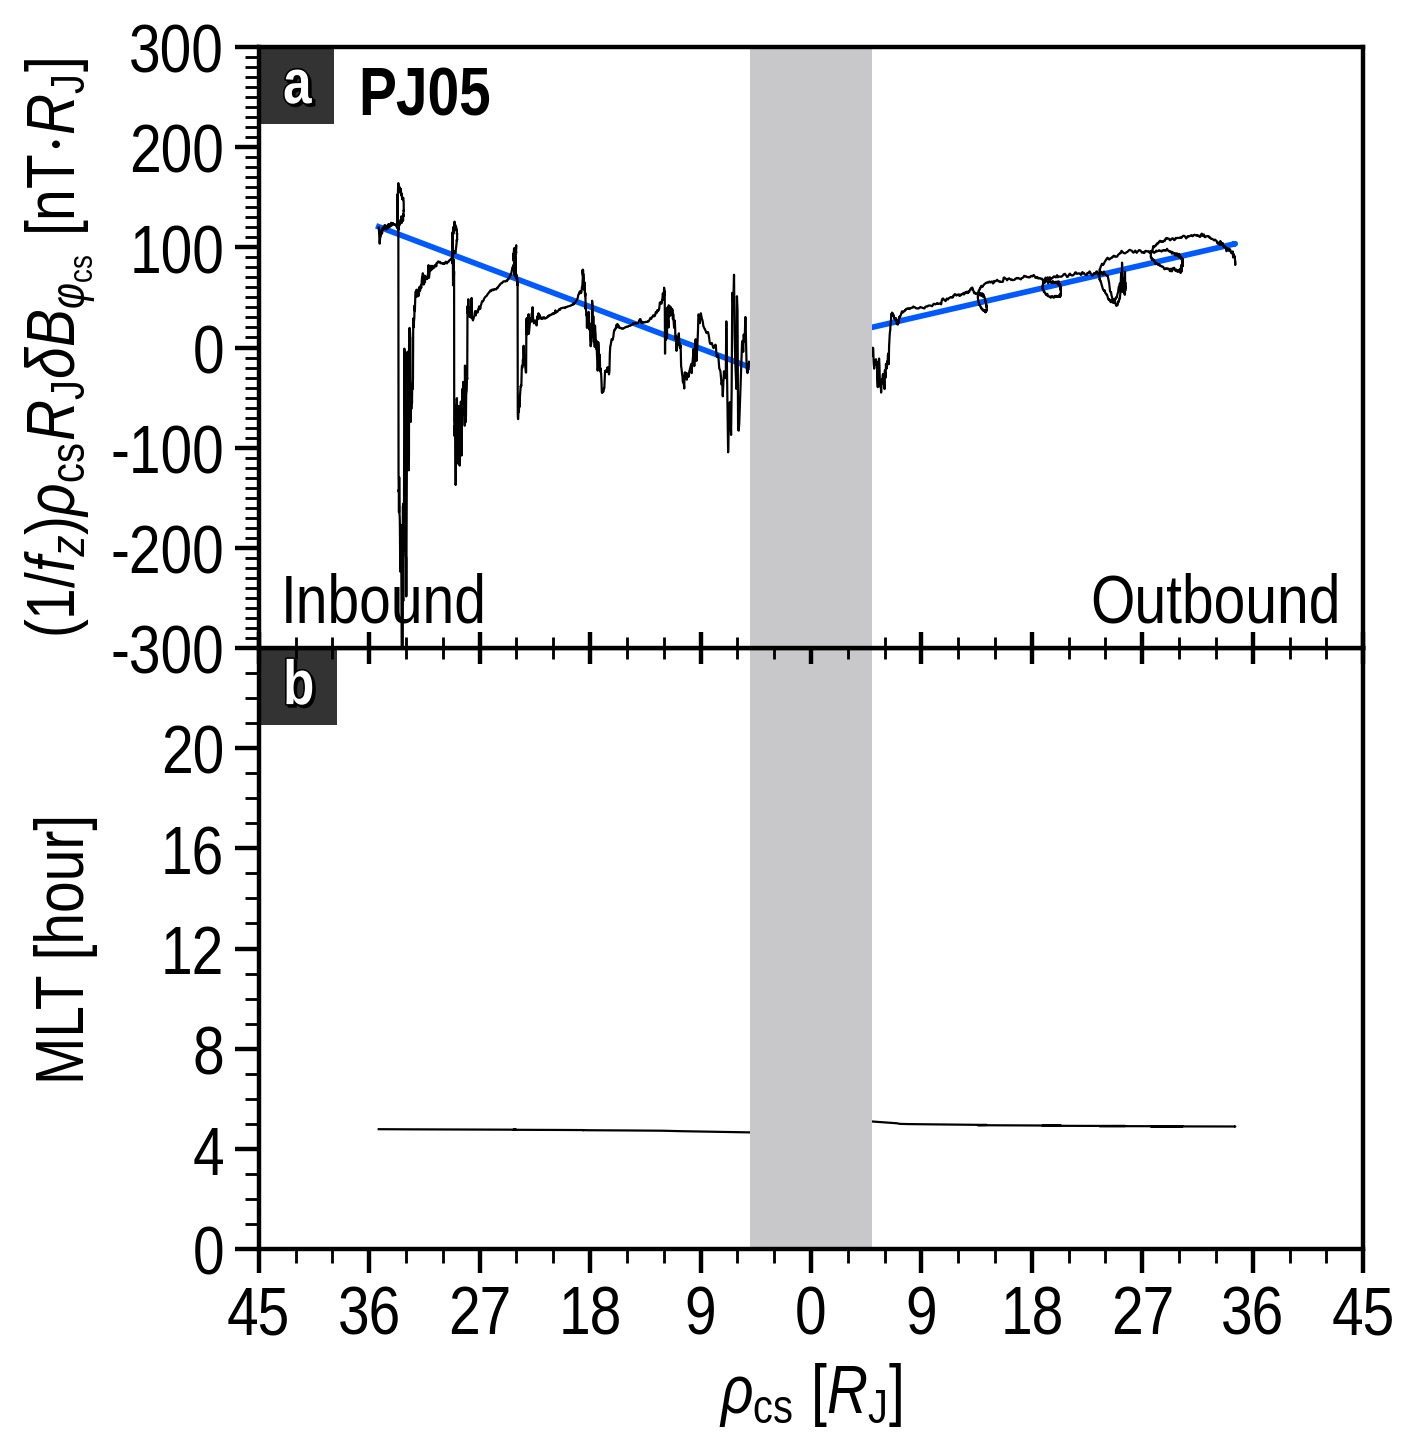

In [108]:
# ===========================================================
# Plot
# ===========================================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.2, 6.5), dpi='L')
F.initialize()

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=-45.0,
            max=45.0,
            ticks=np.arange(-45, 45+1, 9),
            ticklabels=np.abs(np.arange(-45, 45+1, 9)),
            minor_num=3)
F.set_yaxis(ax_idx=0,
            label=r'$(1/f_z) \rho_{\rm cs}R_{\rm J} \delta B_{\varphi_{\rm cs}}$ [nT$\cdot R_{\rm J}$]',
            min=-300, max=300,
            ticks=np.linspace(-300, 300, 7),
            ticklabels=np.linspace(-300, 300, 7, dtype=int),
            minor_num=10)
F.set_yaxis(ax_idx=1,
            label=r'MLT [hour]',
            min=0, max=24,
            ticks=np.arange(0, 24, 4),
            ticklabels=np.arange(0, 24, 4, dtype=int),
            minor_num=4)

# The plot
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]

rho_cs_inb = rho_cs[in_30rj:in_5rj]
z_cs_inb = z_cs[in_30rj:in_5rj]
dBphi_cs_inb = dBphi_cs[in_30rj:in_5rj]
dBphi2_cs_inb = dBphi2_cs[in_30rj:in_5rj]
JunoMLT_inb = JunoMLT[in_30rj:in_5rj]
rho_cs_outb = rho_cs[out_5rj:out_30rj]
z_cs_outb = z_cs[out_5rj:out_30rj]
dBphi_cs_outb = dBphi_cs[out_5rj:out_30rj]
dBphi2_cs_outb = dBphi2_cs[out_5rj:out_30rj]
JunoMLT_outb = JunoMLT[out_5rj:out_30rj]

# INBOUND OBSERVATIONS
g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
f_z = -np.sign(z_cs_inb)*g_rho
f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, z_cs_inb/2.5)
eps = 1e-6
f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
y_obs = (1/f_z)*rho_cs_inb*dBphi_cs_inb
F.ax[0].plot(-rho_cs_inb,
             y_obs,
             color='k',
             linewidth=0.7, label='Observations', zorder=2.0)

# INBOUND weighted linear fit
g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
f_z = -np.sign(z_cs_inb)*g_rho
f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, -g_rho*z_cs_inb/2.5)
eps = 1e-6
f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
a, b, sigma_a, sigma_b = weighted_linear_fit(
    rho_cs_inb*RJ,
    (1/f_z)*(rho_cs_inb*RJ)*(dBphi_cs_inb*1E-9),
    np.abs(f_z))
a_fit_result += [a]             # beta [T]
b_fit_result += [b]             # alpha [T m]
sig_a_fit_result += [sigma_a]   # beta [T]
sig_b_fit_result += [sigma_b]   # alpha [T m]
Juno_MLT_result += [JunoMLT_inb[0]]
in_out_result += [1]
Juno_pj_result += [PJ_num]
RMSE_result += [math.sqrt(
    np.sum((y_obs-(a*rho_cs_inb*RJ+b)*1E+9/RJ)**2)/in_num
)]
F.ax[0].plot(-rho_cs_inb,
             (a*rho_cs_inb*RJ+b)*1E+9/RJ,
             color=UC.blue,
             linewidth=1.8, label='Weighted', zorder=1.0)

# OUTBOUND OBSERVATIONS
g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
f_z = -np.sign(z_cs_outb)*g_rho
f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, z_cs_outb/2.5)
eps = 1e-6
f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
y_obs = (1/f_z)*rho_cs_outb*dBphi_cs_outb
F.ax[0].plot(rho_cs_outb,
             y_obs,
             color='k',
             linewidth=0.7, label='Observations', zorder=2.0)

# OUTBOUND weighted linear fit
if rho_cs_outb.size > 4:
    g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
    f_z = -np.sign(z_cs_outb)*g_rho
    f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, -g_rho*z_cs_outb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    a, b, sigma_a, sigma_b = weighted_linear_fit(
        rho_cs_outb*RJ,
        (1/f_z)*(rho_cs_outb*RJ)*(dBphi_cs_outb*1E-9),
        np.abs(f_z))
    a_fit_result += [a]             # beta [T]
    b_fit_result += [b]             # alpha [T m]
    sig_a_fit_result += [sigma_a]   # beta [T]
    sig_b_fit_result += [sigma_b]   # alpha [T m]
    Juno_MLT_result += [JunoMLT_outb[-1]]
    in_out_result += [-1]
    Juno_pj_result += [PJ_num]
    RMSE_result += [math.sqrt(
        np.sum((y_obs-(a*rho_cs_outb*RJ+b)*1E+9/RJ)**2)/out_num
    )]
    F.ax[0].plot(rho_cs_outb,
                 (a*rho_cs_outb*RJ+b)*1E+9/RJ,
                 color=UC.blue,
                 linewidth=1.8, label='Weighted', zorder=1.0)

# MLT
F.ax[1].plot(-rho_cs_inb,
             JunoMLT_inb,
             color='k',
             linewidth=0.7, label='Observations', zorder=2.0)
F.ax[1].plot(rho_cs_outb,
             JunoMLT_outb,
             color='k',
             linewidth=0.7, label='Observations', zorder=2.0)
# Inner shades
for j in range(2):
    F.ax[j].axvspan(-5.0, 5.0,
                    fc=UC.lightgray, ec=None, zorder=2.5)

F.ax[0].text(0.09, 0.97, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[0].text(0.02, 0.02, 'Inbound',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='bottom',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[0].text(0.98, 0.02, 'Outbound',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='bottom',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)